# Step 5 — denoising VAE representation of paper1's 86 features, then logreg / XGBoost

**Question:** does an unsupervised denoising VAE make the paper's features more predictive? Same people, outcome, LOCO folds, models and grids as step 3; only the inputs change.

Per outer fold (test cycle never seen):

1. Design matrix of the 86 features as for logistic regression in step 1 (one-hot categoricals, scaled numerics), fitted on the 6 training cycles.
2. A VAE (`nhanes/vae.py`) is trained on the training cycles without labels. Denoising: 15% swap noise. Loss: MSE on numeric columns + BCE on one-hot columns + KL. Fixed architecture, no tuning: d → 256 → 128 → 32 (latent) → 128 → 256 → d; Adam 1e-3, batch 256, early stopping (patience 10) on reconstruction loss of 10% of training rows.
3. Each person is encoded as the latent mean (32 numbers).
4. logreg and xgboost tuned by inner LOCO over the training cycles, as in step 1, on **latent** (the 32 latent values only) and **concat** (the 86 original features + the 32 latent values).

The VAE of an outer fold is trained once on all 6 training cycles, so during inner tuning it has seen the (unlabelled) inner validation cycle; the outer test cycle is never seen.

**Output:** `$NHANES_WORK/modeling/step5_vae/` `predictions.csv.gz`, `metrics.csv`, `chosen_params.json`, `report.txt`

`RUN = True` retrains (about 1.5 hours; the VAE uses a GPU with no processes on it if there is one); needs `PAPER1_CSV`. `QUICK = True` with it runs one outer fold, the smallest grids and 3 VAE epochs. `RUN = False` only shows the saved results.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, WORK  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step5_vae
QUICK = False  # with RUN: one outer fold, smallest grids, 3 VAE epochs
PAPER1_CSV = os.environ.get("PAPER1_CSV")  # FullData_rm_dl_bt.csv of the paper1 reproduction (needed with RUN)
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step5_vae"

## Run

In [2]:
if RUN:
    import torch

    from nhanes.loco import (LOGREG_GRID, NOT_FEATURES, XGB_GRID, fit_logreg, fit_xgb, free_gpu, grid,
                             logreg_matrix, metrics, tune)
    from nhanes.paper1 import paper1_table
    from nhanes.vae import VAE, encode, train_vae

    OUT.mkdir(parents=True, exist_ok=True)
    feats, dic = paper1_table(PAPER1_CSV)
    ours = pd.read_csv(WORK / "features" / "features_2005_2018.csv.gz", usecols=NOT_FEATURES)
    data = ours.merge(feats, on="SEQN", how="left", validate="1:1")
    feat_cols = list(dic)
    gpu = free_gpu()
    device = torch.device(f"cuda:{gpu}" if gpu is not None else "cpu")
    print(f"{len(data)} people, {len(feat_cols)} features; VAE on {device}", flush=True)

    cycles = sorted(data.cycle.unique())
    grids = {"logreg": grid(LOGREG_GRID), "xgboost": grid(XGB_GRID)}
    if QUICK:
        grids = {k: v[:1] for k, v in grids.items()}
    zcols = [f"z{i:02d}" for i in range(VAE["latent"])]
    preds, rows, chosen = [], [], {}
    for test_c in cycles[:1] if QUICK else cycles:
        train_cycles = [c for c in cycles if c != test_c]
        is_tr = data.cycle != test_c
        t0 = time.time()
        A, B = logreg_matrix(data.loc[is_tr, feat_cols], data.loc[~is_tr, feat_cols], dic)
        vae, epochs, es_loss = train_vae(A, device, QUICK)
        Z = np.zeros((len(data), VAE["latent"]), dtype=np.float32)
        Z[is_tr.to_numpy()], Z[~is_tr.to_numpy()] = encode(vae, A, device), encode(vae, B, device)
        zdf = pd.DataFrame(Z, columns=zcols, index=data.index)
        print(f"{test_c} VAE: {A.shape[1]} inputs, {epochs} epochs, early-stop recon loss {es_loss:.2f}, "
              f"{(time.time() - t0) / 60:.1f} min", flush=True)
        inputs = {"latent": (pd.concat([data[NOT_FEATURES], zdf], axis=1), {c: "continuous" for c in zcols}),
                  "concat": (pd.concat([data, zdf], axis=1), {**dic, **{c: "continuous" for c in zcols}})}
        for rep, (frame, d) in inputs.items():
            tr, te = frame[is_tr], frame[~is_tr]
            Xtr, Xte = tr.drop(columns=NOT_FEATURES), te.drop(columns=NOT_FEATURES)
            for model in ["logreg", "xgboost"]:
                t1 = time.time()
                params, inner_auc = tune(model, frame, train_cycles, d, grids[model])
                if model == "logreg":
                    P, Q = logreg_matrix(Xtr, Xte, d)
                    prob = fit_logreg(P, tr.depression, params).predict_proba(Q)[:, 1]
                else:
                    fit_p = {k: v for k, v in params.items() if k != "n_estimators"}
                    prob = fit_xgb(Xtr, tr.depression, None, None, fit_p,
                                   n_estimators=params["n_estimators"]).predict_proba(Xte)[:, 1]
                name = f"vae_{rep}+{model}"
                chosen[f"{name}|{test_c}"] = {**params, "inner_auroc": round(inner_auc, 4), "vae_epochs": epochs}
                preds.append(pd.DataFrame({"SEQN": te.SEQN, "cycle": test_c, "model": name, "depression": te.depression,
                                           "weight": te.WTMEC2YR, "prob": prob}))
                rows.append({"model": name, "test_cycle": test_c, **metrics(te.depression, prob, te.WTMEC2YR),
                             "minutes": round((time.time() - t1) / 60, 1)})
                print(f"{test_c} {name}: AUROC {rows[-1]['auroc']:.3f}  {params}  {rows[-1]['minutes']} min", flush=True)

    pred, met = pd.concat(preds, ignore_index=True), pd.DataFrame(rows)
    pred.to_csv(OUT / "predictions.csv.gz", index=False)
    met.to_csv(OUT / "metrics.csv", index=False)
    (OUT / "chosen_params.json").write_text(json.dumps(chosen, indent=1))
    step3 = RESULTS / "step3_paper1" / "metrics.csv"
    if step3.exists():
        met = pd.concat([pd.read_csv(step3).assign(model=lambda m: "raw+" + m.model), met], ignore_index=True)
    summary = met.groupby("model", sort=False)[["auroc", "auroc_weighted", "auprc", "brier"]].agg(["mean", "std"]).round(3)
    lines = ["leave-one-cycle-out, outcome PHQ-9 >= 10; features of Dang et al. (2024) through a denoising VAE",
             "raw+ = step 3 (the 86 features as they are); vae_latent = 32 latent values; vae_concat = 86 + 32", "",
             "mean (sd) over test cycles, each cycle weighted equally:", summary.to_string(), "",
             "AUROC per test cycle:", met.pivot(index="test_cycle", columns="model", values="auroc").round(3).to_string(),
             "", f"VAE device: {device}"]
    (OUT / "report.txt").write_text("\n".join(lines) + "\n")

## Results (raw+ = step 3, the 86 features as they are)

In [3]:
print((OUT / "report.txt").read_text())

leave-one-cycle-out, outcome PHQ-9 >= 10; features of Dang et al. (2024) through a denoising VAE
raw+ = step 3 (the 86 features as they are); vae_latent = 32 latent values; vae_concat = 86 + 32

mean (sd) over test cycles, each cycle weighted equally:
                    auroc        auroc_weighted         auprc         brier       
                     mean    std           mean    std   mean    std   mean    std
model                                                                             
raw+logreg          0.792  0.014          0.796  0.013  0.322  0.033  0.179  0.009
raw+xgboost         0.791  0.013          0.796  0.014  0.316  0.027  0.172  0.007
vae_latent+logreg   0.772  0.011          0.774  0.010  0.263  0.026  0.196  0.005
vae_latent+xgboost  0.772  0.012          0.777  0.009  0.276  0.027  0.185  0.008
vae_concat+logreg   0.793  0.013          0.797  0.011  0.318  0.035  0.180  0.010
vae_concat+xgboost  0.791  0.012          0.795  0.012  0.313  0.023  0.175  0.005



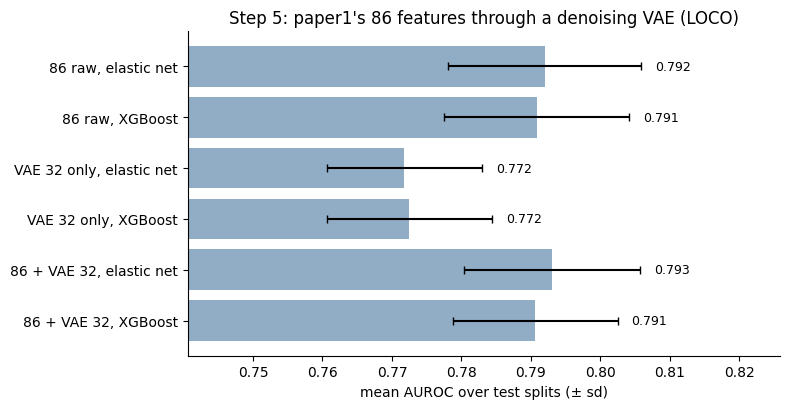

In [4]:
met = pd.concat([pd.read_csv(RESULTS / "step3_paper1" / "metrics.csv").assign(model=lambda m: "raw+" + m.model),
                 pd.read_csv(OUT / "metrics.csv")], ignore_index=True)
names = {f"{r}+{m}": f"{label}, {'elastic net' if m == 'logreg' else 'XGBoost'}"
         for r, label in [("raw", "86 raw"), ("vae_latent", "VAE 32 only"), ("vae_concat", "86 + VAE 32")]
         for m in ["logreg", "xgboost"]}
summary = plots.summarise(met, order=list(names)).rename(index=names)
plots.mean_auroc_bars(summary, title="Step 5: paper1's 86 features through a denoising VAE (LOCO)")
plots.show()